In [2]:
import sys
import datetime
import xarray as xr
import geopandas
import numpy as np
import pandas as pd
# pip install psycopg2

In [3]:
## Define connection
from sqlalchemy import create_engine

host = "bdclimop-usr.meteo.fr"
user = "anonymous"
passwd = "anonymous"
database = "bdclim"

engine_bdclim = create_engine(
    f"postgresql+psycopg2://{user}:{passwd}@{host}/{database}",
    connect_args={"connect_timeout": 5},
)


In [4]:
from sqlalchemy import MetaData, select, Table

## Select table of interest :
metadata = MetaData()
table_poste = Table("poste", metadata, autoload_with=engine_bdclim)
table_h = Table("h", metadata, autoload_with=engine_bdclim)
table_q = Table("q", metadata, autoload_with=engine_bdclim)

## type and retrieve request using pandas


## Request all poste from poste table
req = select(
    table_poste.c.num_poste,
    table_poste.c.nom_usuel,
    table_poste.c.lat_dg,
    table_poste.c.lon_dg,
    table_poste.c.lambx_93,
    table_poste.c.lamby_93,
    table_poste.c.alti,
    table_poste.c.reseau_poste_actuel,
)
with engine_bdclim.connect() as conn:
    df_meta = pd.read_sql_query(req, conn)

## Select only postes in Grandes Rousses domain
df_meta = df_meta[df_meta["alti"] >= 600]
df_meta = df_meta[df_meta["lon_dg"] >= 6.0183935742076571]
df_meta = df_meta[df_meta["lon_dg"] <= 6.4858571654639974]
df_meta = df_meta[df_meta["lat_dg"] >= 44.9961068128740536]
df_meta = df_meta[df_meta["lat_dg"] <= 45.2365163292256511]
## Transform it into xarray
ds_metadata = df_meta.set_index("num_poste").to_xarray()

/tmp/ipykernel_9888/449558912.py:5: SAWarning: Did not recognize type 'geometry' of column 'pos_geo_4326'
  table_poste = Table("poste", metadata, autoload_with=engine_bdclim)


Request neigetot, i.e. hourly data

In [5]:
#### Hourly data

## Request data from table H : MTO

# output_path = "/cnrm/cen/users/NO_SAVE/monteirod/Reference_Dataset/OBS_in_situ/BDCLIM/DATA/"

## Request data from table H :
var = "neigetot"
ls_year = [2021, 2023]

# Retrieve data for num_poste selected above, we stored them into ls_station
ls_station = list(map(int, ds_metadata.num_poste.values))

# For large request to avoid kick out from server, we cut into multiple request (each 10 stations here)
n = 10
station_index = list(np.arange(0, len(ls_station), n))
station_index.append(len(ls_station))

## Retrieve data along with dat and num_poste matching stations in ls_stations for dat sup to XXXX and inf to XXXX
df_i = []
for i in range(0, len(station_index) - 1):
    print(station_index[i])
    req = (
        select(table_h.c[var], table_h.c.dat, table_h.c.num_poste)
        .where(table_h.c.num_poste.in_(ls_station[station_index[i] : station_index[i + 1]]))
        .where((table_h.c.dat >= datetime.datetime(ls_year[0], 1, 1)))
        .where((table_h.c.dat <= datetime.datetime(ls_year[-1], 1, 1)))
    )
    with engine_bdclim.connect() as conn:
        df_i.append(pd.read_sql_query(req, conn))

## Merge all
df = pd.concat(df_i)

# Transform date into datetime64 (numpy format)
df["dat"] = pd.to_datetime(df["dat"])

# Drop duplicates entry if any and transform into xarray dataset
ds = df.drop_duplicates(subset=["num_poste", "dat"]).set_index(["dat", "num_poste"])[[var]].to_xarray()

## Add coordinates of interest from ds_metadata

# Subselect stations in metadata
intersect_postes = list(set(ds.num_poste.values) & set(ds_metadata.num_poste.values))
ds = xr.merge([ds, ds_metadata.sel(num_poste=intersect_postes)])

# Rename and set coords
ds = ds.rename(
    {
        "alti": "ZS",
        "lat_dg": "lat",
        "lon_dg": "lon",
        "lambx_93": "x",
        "lamby_93": "y",
        "nom_usuel": "Station_Name",
        "dat": "time",
    }
).set_coords(["ZS", "lat", "lon", "x", "y", "Station_Name", "reseau_poste_actuel"])

## First remove stations where no t2m obs at all
# ds = ds.dropna(dim = 'num_poste', how = 'all')

# ## Save as netcdf
# ds.to_netcdf('/cnrm/cen/users/NO_SAVE/monteirod/Reference_Dataset/OBS_in_situ/BDCLIM/DATA/bdclim_extract_SAFRAN_'+var+'_table_H_'+str(ls_year[0])+'-'+str(ls_year[-1])+'.nc')


0
10
20
30
40
50
60
70
80
90
100
110


/tmp/ipykernel_9888/1376083428.py:33: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat(df_i)


We keep only the daily mean

In [31]:
ds_dm = ds.resample(time="D").mean().data_vars["neigetot"].sel(time=slice("2021-08", "2022-07"))


def filter_dead_stations(data: xr.DataArray) -> xr.DataArray:
    return data.where(~(np.isnan(data) + (data == 0).all(dim='time')), drop=True)


filtered_dm = filter_dead_stations(ds_dm)
filtered_ds = xr.Dataset(
    data_vars={
        "snow_depth": xr.DataArray(
            filtered_dm.data / 100, # Convert to m
            dims=("time", "num_poste"),
            coords={"time": filtered_dm.time.values + np.timedelta64(12,'h'), "num_poste": filtered_dm.num_poste.values},
        )
    },
)
filtered_ds = filtered_ds.assign_coords(x=("num_poste", filtered_dm.x.values))
filtered_ds = filtered_ds.assign_coords(y=("num_poste", filtered_dm.y.values))
filtered_ds = filtered_ds.assign_coords(lon=("num_poste", filtered_dm.lon.values))
filtered_ds = filtered_ds.assign_coords(lat=("num_poste", filtered_dm.lat.values))
filtered_ds = filtered_ds.assign_coords(elevation=("num_poste", filtered_dm.ZS.values))
filtered_ds = filtered_ds.assign_coords(station_name=("num_poste", filtered_dm.Station_Name.values))
filtered_ds.to_netcdf(
    "/home/imperatoren/work/edelweiss_assimilation/observations/grandesrousses250m/bdclim/snow_depth_daily_avg.nc"
)

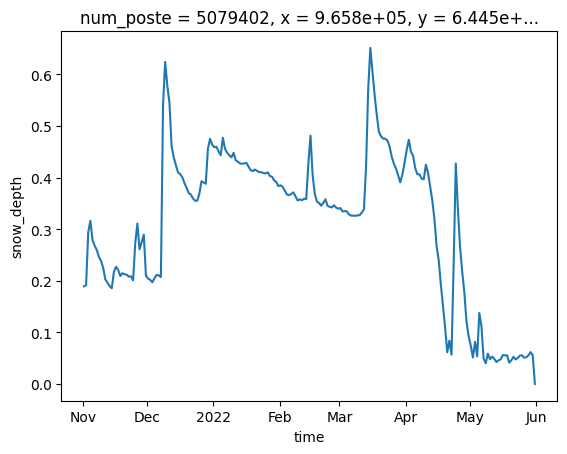

In [30]:
line=filtered_ds.sel(time=slice('2021-11', '2022-05')).isel(num_poste=4)
# print(line.site_name.values)
# print(np.isnan(line.snow_depth))
line.data_vars['snow_depth'].plot.line()

OTHER DAILY DATA 
neigetot06: snow height measured at 6 am
neigetotx: maximal snow height measured in a day

In [ ]:
########## Daily data
## Request data from table H : MTO


## Request data from table H :
var = ["neigetotx", "neigetot06"]
# var = ["neigetot"]
ls_year = [2021, 2023]

# Retrieve data for num_poste selected above, we stored them into ls_station
ls_station = list(map(int, ds_metadata.num_poste.values))

# For large request to avoid kick out from server, we cut into multiple request (each 10 stations here)
n = 10
station_index = list(np.arange(0, len(ls_station), n))
station_index.append(len(ls_station))

## Retrieve data along with dat and num_poste matching stations in ls_stations for dat sup to XXXX and inf to XXXX
df_j = []
for j in range(0, len(var)):
    df_i = []
    for i in range(0, len(station_index) - 1):
        print(station_index[i])
        req = (
            select(table_q.c[var[j]], table_q.c.dat, table_q.c.num_poste)
            .where(table_q.c.num_poste.in_(ls_station[station_index[i] : station_index[i + 1]]))
            .where((table_q.c.dat >= datetime.datetime(ls_year[0], 1, 1)))
            .where((table_q.c.dat <= datetime.datetime(ls_year[-1], 1, 1)))
        )
        with engine_bdclim.connect() as conn:
            df_i.append(pd.read_sql_query(req, conn))

    ## Merge all
    df_j.append(pd.concat(df_i))


ds_j = [0, 0]

for j in range(0, len(var)):
    # Transform date into datetime64 (numpy format)
    df_j[j]["dat"] = pd.to_datetime(df_j[j]["dat"])

    # Drop duplicates entry if any and transform into xarray dataset
    ds_j[j] = df_j[j].drop_duplicates(subset=["num_poste", "dat"]).set_index(["dat", "num_poste"]).to_xarray()

    ## Add coordinates of interest from ds_metadata

    # Subselect stations in metadata
    intersect_postes = list(set(ds_j[j].num_poste.values) & set(ds_metadata.num_poste.values))
    ds_j[j] = xr.merge([ds_j[j], ds_metadata.sel(num_poste=intersect_postes)])

    # Rename and set coords
    ds_j[j] = (
        ds_j[j]
        .rename({"alti": "ZS", "lat_dg": "lat", "lon_dg": "lon", "nom_usuel": "Station_Name", "dat": "time"})
        .set_coords(["ZS", "lat", "lon", "Station_Name", "reseau_poste_actuel"])
    )

    ds_j[j] = ds_j[j].dropna(dim="num_poste", how="all")

    # # ## Save as netcdf
    # ds_j[j].to_netcdf('/cnrm/cen/users/NO_SAVE/monteirod/Reference_Dataset/OBS_in_situ/BDCLIM/DATA/bdclim_extract_SAFRAN_'+var[j]+'_table_q_'+str(ls_year[0])+'-'+str(ls_year[-1])+'.nc')


0
10
20
30
40
50
60
70
80
90
100
110


/tmp/ipykernel_30310/1554826013.py:34: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_j.append(pd.concat(df_i))


0
10
20
30
40
50
60
70
80
90
100
110


/tmp/ipykernel_30310/1554826013.py:34: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_j.append(pd.concat(df_i))


In [ ]:
ds_x = ds_j[0].data_vars["neigetotx"].sel(time=slice("2021-08", "2022-07"))
ds_06 = ds_j[1].data_vars["neigetot06"].sel(time=slice("2021-08", "2022-07"))

filtered_dm = filter_dead_stations(ds_dm)
filtered_06 = filter_dead_stations(ds_06)
filtered_x = filter_dead_stations(ds_x)

station_list = []
station_list = filtered_dm.coords["Station_Name"].values
[station_list.extend(st) for st in filtered_06.coords["Station_Name"].values if st not in station_list]
[station_list.extend([st]) for st in filtered_x.coords["Station_Name"].values if st not in station_list]
station_list

array(['LAC NOIR-EDFNIVO', 'LA MEIJE-NIVOSE', 'La Grave - La Meije',
       'LA GRAVE 3200 M', 'GALIBIER-NIVOSE', "VILLAR D'ARENE",
       'AIGLETON-NIVOSE', 'AURIS-EN-OISANS', 'AGNELIN-EDFNIVO',
       "ALPE-D'HUEZ", 'L Alpe d Huez (SATA)', 'L Alpe d Huez 2350',
       'Les 2 Alpes (Toura NE)', 'Les 2 ALpes Jandri', 'Olmet', 'VAUJANY',
       'VAUJANY-NIVO', 'ALBIEZ', 'Les Karellis', 'MONTFROID-EDFNIVO',
       "ST JEAN D'ARVES_SAPC", "ST-SORLIN D'ARVES", "ST SORLIN D'ARVES",
       'LES ROCHILLES-NIVOSE', 'Valloire'], dtype=object)

In [ ]:
ds_x.sel(time=slice("2021-11", "2022-06")).where(~np.isnan(ds_dm).all(dim="time"), drop=True)

<xarray.Dataset> Size: 3kB
Dimensions:              (time: 242, num_poste: 27)
Coordinates:
  * time                 (time) datetime64[ns] 2kB 2021-11-01 ... 2022-06-30
  * num_poste            (num_poste) int64 216B 5063003 5063402 ... 73306403
    Station_Name         (num_poste) object 216B 'LAC NOIR-EDFNIVO' ... 'Vall...
    lat                  (num_poste) float64 216B 45.05 45.01 ... 45.09 45.16
    lon                  (num_poste) float64 216B 6.225 6.265 ... 6.469 6.463
    ZS                   (num_poste) int64 216B 2450 3093 2420 ... 2444 2295
    reseau_poste_actuel  (num_poste) object 216B '72' '50' '51' ... '50' '51'
Data variables:
    *empty*

In [ ]:
ds_06.sel(time=slice("2021-11", "2022-06")).where(~np.isnan(ds_dm).all(dim="time"), drop=True)

<xarray.Dataset> Size: 3kB
Dimensions:              (time: 242, num_poste: 27)
Coordinates:
  * time                 (time) datetime64[ns] 2kB 2021-11-01 ... 2022-06-30
  * num_poste            (num_poste) int64 216B 5063003 5063402 ... 73306403
    Station_Name         (num_poste) object 216B 'LAC NOIR-EDFNIVO' ... 'Vall...
    lat                  (num_poste) float64 216B 45.05 45.01 ... 45.09 45.16
    lon                  (num_poste) float64 216B 6.225 6.265 ... 6.469 6.463
    ZS                   (num_poste) int64 216B 2450 3093 2420 ... 2444 2295
    reseau_poste_actuel  (num_poste) object 216B '72' '50' '51' ... '50' '51'
Data variables:
    *empty*

In [ ]:
ds_dm.where(ds.Station_Name == "BESSE", drop=True).isel(num_poste=0).values

array([nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, na

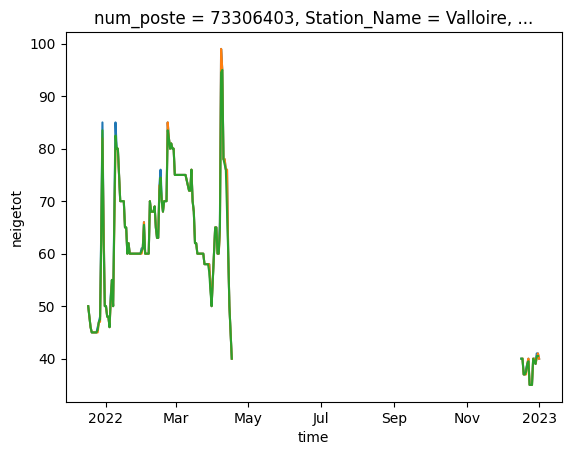

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

ds_j[0].data_vars["neigetotx"].sel(num_poste=73306403).plot.line(ax=ax)
ds_j[1].data_vars["neigetot06"].sel(num_poste=73306403).plot.line(ax=ax)
ds.data_vars["neigetot"].resample(time="D").mean().sel(num_poste=73306403).plot.line(ax=ax)